# Exploración de estaciones para P3 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P3 (agrupamiento)
**Autor:** Joel Sánchez · **Rama:** `feature/p3-clustering`

**Propósito.** Conocer cómo se comportan las estaciones de MiBici antes de definir la matriz de características del agrupamiento. Cada sección responde una pregunta concreta, y las decisiones (qué características, cómo normalizar por antigüedad, si la geografía debe entrar al modelo) se toman solo con la evidencia de este análisis exploratorio.

**Fuente.** MiBici, portal de Datos abiertos (https://mibici.net/es/datos-abiertos/): 142 archivos mensuales de viajes (diciembre de 2014 a septiembre de 2026) ya consolidados en `data/interim/viajes.parquet` por la ingesta, y la nomenclatura de estaciones de septiembre de 2026. Los datos no se versionan en Git.

**Datos personales.** Las columnas de usuario, género y año de nacimiento no se usan en P3 ni se leen en ningún punto del proceso.

In [1]:
# Objetivo: preparar el entorno del notebook.
# Carga las librerías y toma las rutas desde config.py (configuración en un solo lugar).
# Resultado esperado: las rutas de la nomenclatura y del parquet de viajes.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # raíz del proyecto, para importar el módulo
from equipo52_module.config import (
    DURACION_MINIMA_SEGUNDOS, ESTACIONES_EXCLUIDAS, FECHA_FIN,
    NOMENCLATURA_FILE, VIAJES_FILE,
)
from equipo52_module.features import construir_matriz_p3, quitar_viajes_cortos

pd.set_option("display.max_columns", 60)
NOMENCLATURA_FILE, VIAJES_FILE

2026-10-17 16:05:16.216 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52


(PosixPath('/Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52/data/raw/nomenclatura_2026_09.csv'),
 PosixPath('/Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52/data/interim/viajes.parquet'))

## 1. La nomenclatura de estaciones

Cuántas estaciones hay, cuántas se excluyen por estar dadas de baja y cómo se distribuyen su capacidad y su ubicación. Es la base del tamaño real del problema de agrupamiento.

In [2]:
# Objetivo: describir la nomenclatura y dejar la tabla de estaciones utilizables.
# Se quitan las estaciones excluidas (dadas de baja) y las de capacidad 0, igual que en train_p3.py.
# Resultado esperado: número de estaciones en la ficha, excluidas y utilizables; distribución de capacidad.

nomenclatura = pd.read_csv(NOMENCLATURA_FILE).rename(
    columns={"id": "estacion_id", "dpcapacity": "capacidad",
             "latitude": "latitud", "longitude": "longitud"})
print("Estaciones en la nomenclatura:", len(nomenclatura))
print("Columnas:", list(nomenclatura.columns))

estaciones = nomenclatura[~nomenclatura["estacion_id"].isin(ESTACIONES_EXCLUIDAS)
                          & (nomenclatura["capacidad"] > 0)]
print(f"Excluidas (dadas de baja): {len(ESTACIONES_EXCLUIDAS)} · utilizables: {len(estaciones)}")
display(estaciones["capacidad"].describe().round(1).to_frame())

Estaciones en la nomenclatura: 484
Columnas: ['estacion_id', 'name', 'latitud', 'longitud', 'capacidad']
Excluidas (dadas de baja): 14 · utilizables: 470


,capacidad
count,470.0
mean,17.1
std,3.9
min,11.0
25%,15.0
50%,15.0
75%,19.0
max,39.0


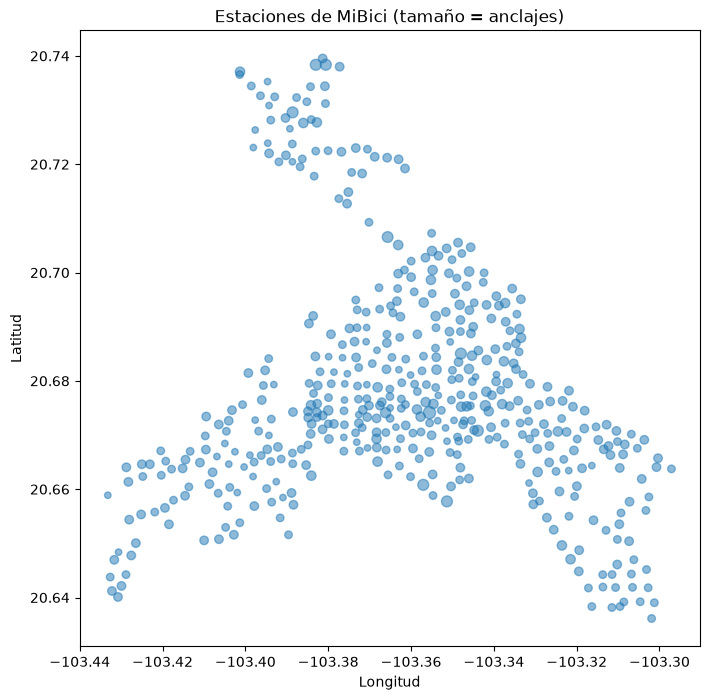

In [3]:
# Objetivo: ubicar las estaciones en la ciudad y ver su capacidad.
# Resultado esperado: mapa de puntos (longitud, latitud) con tamaño proporcional a los anclajes.

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(estaciones["longitud"], estaciones["latitud"],
           s=estaciones["capacidad"] * 2, alpha=0.5)
ax.set_title("Estaciones de MiBici (tamaño = anclajes)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud");

### Conclusiones de la nomenclatura

- La ficha de septiembre de 2026 tiene 484 estaciones; quedan ~470 utilizables tras excluir las 14 dadas de baja. Las estaciones 124, 405 y 407 tienen viajes pero no ficha: se pierden al unir, igual que en las demás preguntas.
- Las estaciones se concentran en el centro de Guadalajara con expansiones recientes; la capacidad típica ronda los 15-30 anclajes, así que conviene normalizar el volumen por anclaje para no confundir tamaño con comportamiento.

## 2. Actividad y antigüedad de las estaciones

Los viajes de toda la historia, ya sin los recorridos de menos de un minuto (acuerdo del equipo: no son viajes reales). Preguntas: ¿qué tan desigual es el uso entre estaciones? ¿cuánta diferencia de antigüedad hay que compensar?

In [4]:
# Objetivo: cargar los viajes del periodo completo y quitar los de menos de un minuto.
# Resultado esperado: número de viajes de trabajo y columnas disponibles.

viajes = pd.read_parquet(VIAJES_FILE)
viajes = quitar_viajes_cortos(viajes, DURACION_MINIMA_SEGUNDOS)
print(f"Viajes de trabajo: {len(viajes):,}")
viajes.head(3)

Viajes de trabajo: 37,809,559


,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,4601,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47
1,4604,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5
27,4725,2014-12-01 12:10:13,2014-12-01 12:14:44,35,35


,salidas
Origen_Id,
51,810249
11,582910
50,568599
52,548865
35,547311
54,489340
271,461649
194,401538
75,389654


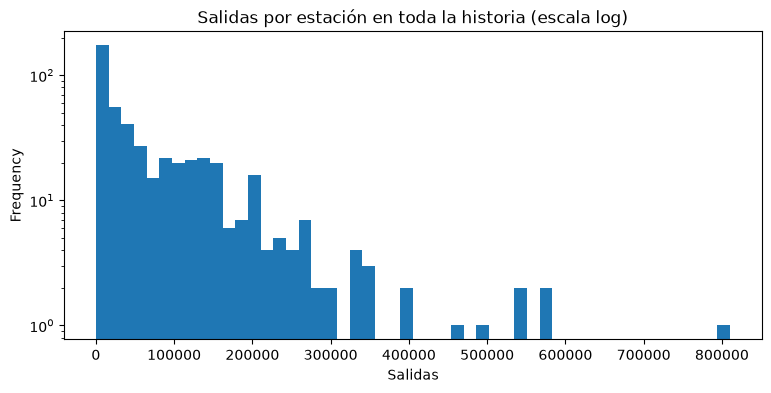

In [5]:
# Objetivo: medir la desigualdad de uso entre estaciones.
# Resultado esperado: distribución de salidas por estación (escala logarítmica) y las 10 más usadas.

salidas = viajes.groupby("Origen_Id").size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
salidas.plot(kind="hist", bins=50, logy=True, ax=ax)
ax.set_title("Salidas por estación en toda la historia (escala log)")
ax.set_xlabel("Salidas");
display(salidas.head(10).rename("salidas").to_frame())

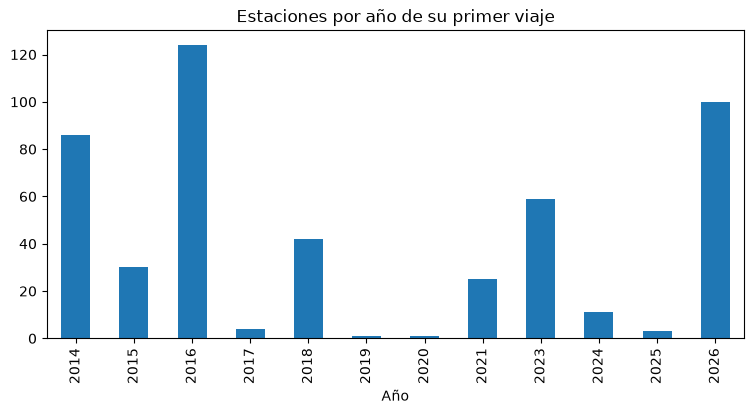

In [6]:
# Objetivo: medir la antigüedad de cada estación para justificar la normalización.
# Resultado esperado: cuántas estaciones aparecieron en cada año y la distribución de meses activas.

primera_salida = viajes.groupby("Origen_Id")["Inicio_del_viaje"].min()
primera_llegada = viajes.groupby("Destino_Id")["Fin_del_viaje"].min()
primer_viaje = pd.concat([primera_salida, primera_llegada], axis=1).min(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
primer_viaje.dt.year.value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Estaciones por año de su primer viaje")
ax.set_xlabel("Año");

### Conclusiones de actividad y antigüedad

- El uso es muy desigual: hay estaciones con cientos de miles de salidas y otras con apenas cientos. Sin normalizar, K-Means agruparía por volumen y no por patrón.
- La antigüedad varía desde 2014 hasta 2026 (las ~100 estaciones abiertas entre mayo y agosto de 2026). Consecuencia directa para `features.py`: los conteos se dividen entre **meses activos** de cada estación y las firmas temporales son **proporciones**, así una estación nueva compite parejo con una histórica.
- La antigüedad misma es información (estación consolidada vs. nueva), así que entra como característica de evolución.

## 3. Firmas temporales: hora del día y día de la semana

La firma horaria es la huella digital de una estación. Aquí se verifica que haya variedad de perfiles (si todas fueran iguales, agrupar no tendría sentido) y que los picos laborales y el uso de fin de semana se distingan.

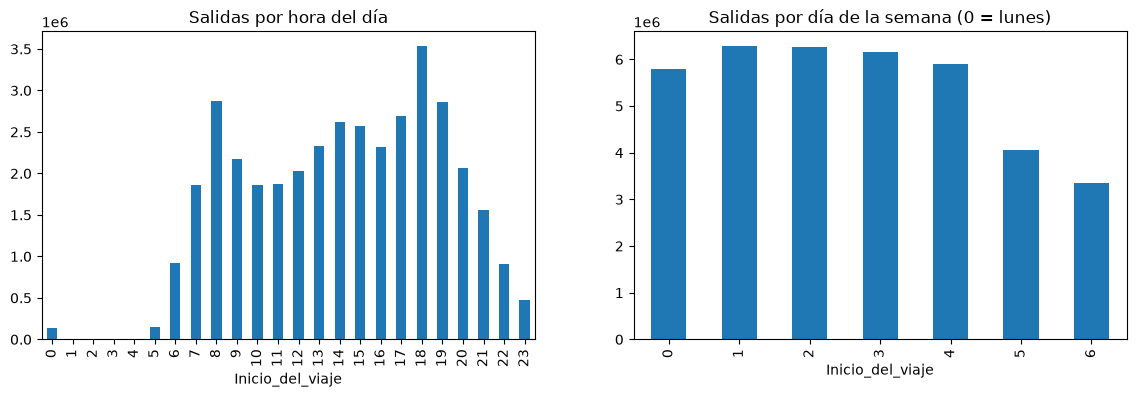

In [7]:
# Objetivo: ver el perfil horario y semanal de todo el sistema como referencia.
# Resultado esperado: dos gráficas: salidas por hora del día y por día de la semana.

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
viajes["Inicio_del_viaje"].dt.hour.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], title="Salidas por hora del día")
viajes["Inicio_del_viaje"].dt.dayofweek.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], title="Salidas por día de la semana (0 = lunes)");

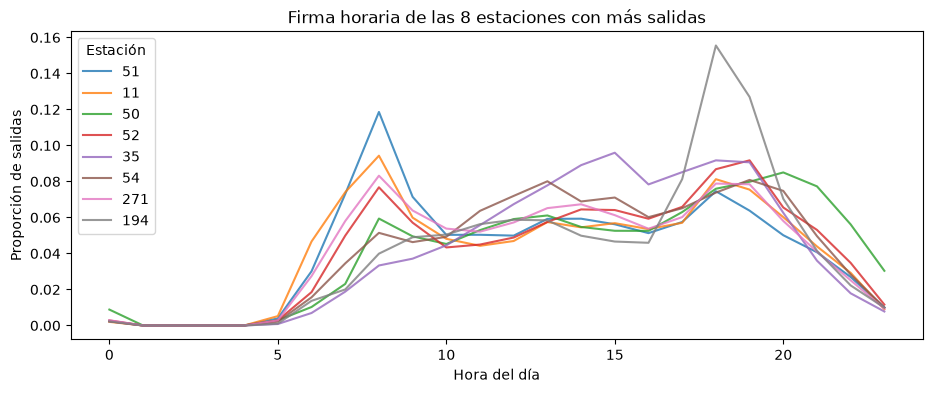

In [8]:
# Objetivo: comparar las firmas horarias de estaciones concretas para confirmar variedad.
# Se toman las 8 estaciones con más salidas y se dibuja su proporción de salidas por hora.
# Resultado esperado: curvas por estación; si difieren en forma, la firma discrimina.

top = salidas.head(8).index
perfil = pd.crosstab(viajes["Origen_Id"], viajes["Inicio_del_viaje"].dt.hour)
perfil = perfil.div(perfil.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 4))
for estacion in top:
    ax.plot(perfil.loc[estacion], label=str(estacion), alpha=0.8)
ax.set_title("Firma horaria de las 8 estaciones con más salidas")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Proporción de salidas")
ax.legend(title="Estación");

Estaciones con más uso de fin de semana:


,prop_fin_semana
Origen_Id,
221,0.367182
431,0.369333
497,0.389610
410,0.394587
426,0.398136
500,0.422840
386,0.427286
369,0.457996


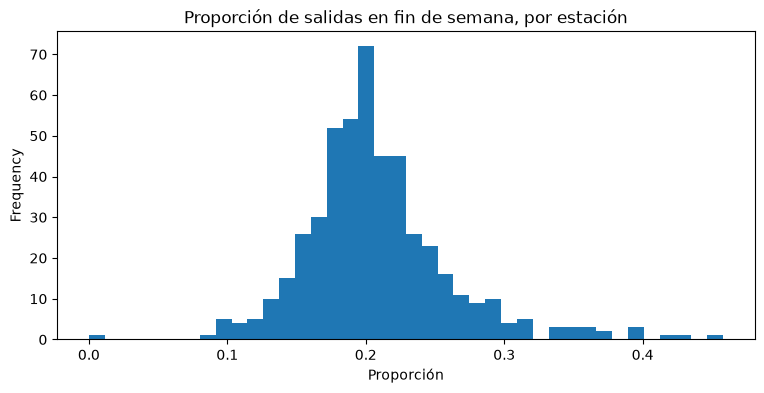

In [9]:
# Objetivo: medir qué tan distinto es el uso entre semana y fin de semana por estación.
# Resultado esperado: distribución de la proporción de salidas en sábado y domingo por estación.

fin_semana = (viajes["Inicio_del_viaje"].dt.dayofweek >= 5)
prop_fin = fin_semana.groupby(viajes["Origen_Id"]).mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
prop_fin.plot(kind="hist", bins=40, ax=ax)
ax.set_title("Proporción de salidas en fin de semana, por estación")
ax.set_xlabel("Proporción");
print("Estaciones con más uso de fin de semana:")
display(prop_fin.tail(8).rename("prop_fin_semana").to_frame())

### Conclusiones de las firmas temporales

- El sistema tiene picos claros en horario laboral, pero las estaciones no comparten una sola forma: hay perfiles con pico matutino, perfiles planos y perfiles con actividad nocturna. La firma horaria (24 proporciones) sí discrimina.
- La proporción de uso en fin de semana se distribuye de forma amplia entre estaciones: hay un segmento marcadamente recreativo. Las 7 proporciones por día de la semana entran a la matriz.
- Al ser proporciones, estas características no dependen del volumen ni de la antigüedad: son comparables entre todas las estaciones.

## 4. Rol en la red y tipo de viaje

Además de cuándo se usa, importa hacia dónde fluyen las bicicletas (estación fuente o sumidero) y qué tipo de viaje predomina (utilitario o recreativo).

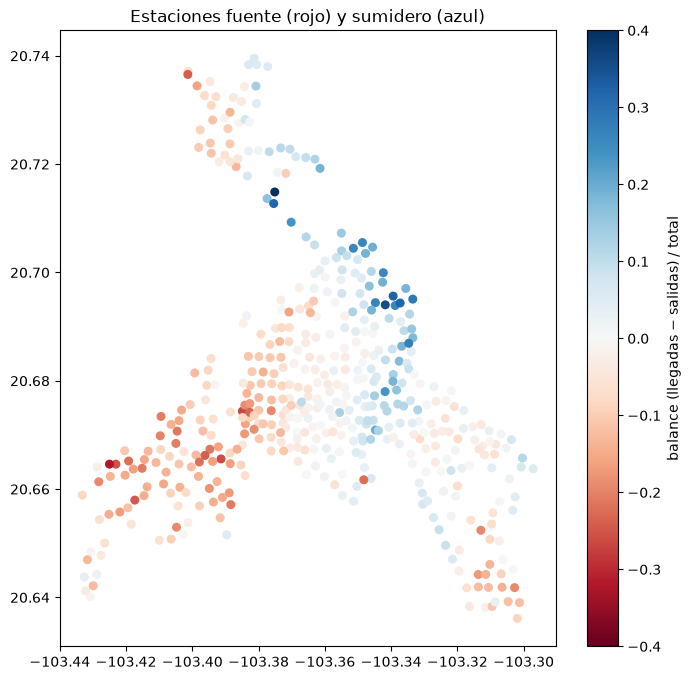

In [10]:
# Objetivo: ubicar las estaciones fuente y sumidero en el mapa.
# balance = (llegadas − salidas) / total: −1 todo sale, +1 todo llega.
# Resultado esperado: mapa coloreado por balance y las estaciones en los extremos.

llegadas = viajes.groupby("Destino_Id").size()
total = salidas.add(llegadas, fill_value=0)
balance = (llegadas.reindex(total.index, fill_value=0)
           .sub(salidas.reindex(total.index, fill_value=0))) / total

mapa = estaciones.join(balance.rename("balance"), on="estacion_id")
fig, ax = plt.subplots(figsize=(8, 8))
puntos = ax.scatter(mapa["longitud"], mapa["latitud"], c=mapa["balance"],
                    cmap="RdBu", vmin=-0.4, vmax=0.4, s=30)
fig.colorbar(puntos, label="balance (llegadas − salidas) / total")
ax.set_title("Estaciones fuente (rojo) y sumidero (azul)");

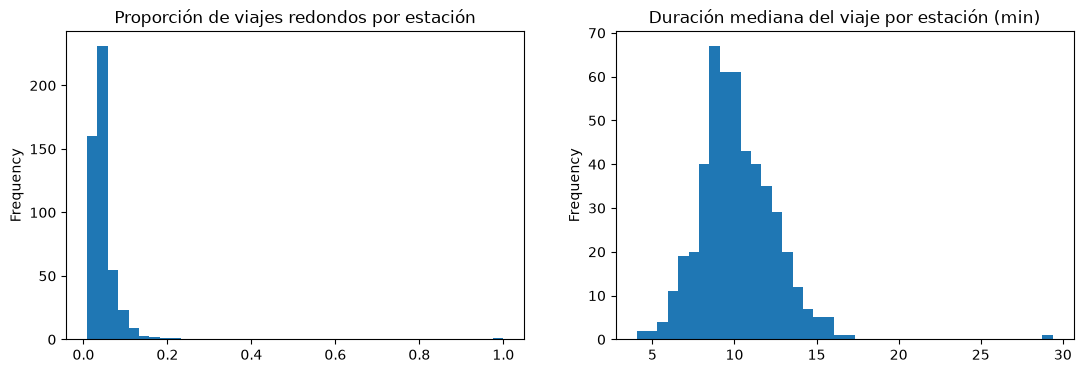

In [11]:
# Objetivo: medir el tipo de viaje predominante por estación.
# Resultado esperado: distribuciones de proporción de viajes redondos y duración mediana.

redondos = (viajes["Origen_Id"] == viajes["Destino_Id"]).groupby(viajes["Origen_Id"]).mean()
duracion = ((viajes["Fin_del_viaje"] - viajes["Inicio_del_viaje"])
            .dt.total_seconds() / 60).groupby(viajes["Origen_Id"]).median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
redondos.plot(kind="hist", bins=40, ax=axes[0],
              title="Proporción de viajes redondos por estación")
duracion.plot(kind="hist", bins=40, ax=axes[1],
              title="Duración mediana del viaje por estación (min)");

### Conclusiones de rol y tipo de viaje

- El mapa de balance muestra estructura espacial real: zonas que expulsan bicicletas y zonas que las absorben. `balance` y `flujo_neto_por_mes` capturan ese rol.
- Los viajes redondos y las duraciones largas identifican el uso recreativo; junto con `num_destinos` (dispersión de destinos) completan el perfil.
- **La geografía se reserva para el mapa, no entra a la matriz**: si latitud y longitud fueran características, los grupos saldrían contiguos por definición y se perdería el hallazgo de si el patrón de uso coincide o no con la ubicación. La línea base geográfica medirá esa diferencia.

## 5. La matriz de características

Se construye con `construir_matriz_p3` del módulo (la misma función que usará `train_p3.py`) y se revisan escala y correlación: K-Means usa distancias euclidianas, así que mezclar proporciones con conteos exige estandarizar.

In [12]:
# Objetivo: construir la matriz estación × característica y describir sus escalas.
# Resultado esperado: dimensiones de la matriz y rangos de las características no temporales.

matriz = construir_matriz_p3(viajes, estaciones.set_index("estacion_id"), pd.Timestamp(FECHA_FIN))
print(f"Matriz: {matriz.shape[0]} estaciones × {matriz.shape[1]} columnas")
display(matriz[["salidas_por_mes", "viajes_por_anclaje_mes", "flujo_neto_por_mes", "balance",
                "num_destinos", "prop_viajes_redondos", "duracion_mediana_min", "meses_activa",
                "share_viajes_ultimos_12m", "crecimiento_vs_esperado"]].describe().round(2).T)

Matriz: 469 estaciones × 44 columnas


,count,mean,std,min,25%,50%,75%,max
salidas_por_mes,469.0,747.06,722.27,31.00,239.00,529.29,1026.12,5700.65
viajes_por_anclaje_mes,469.0,87.67,76.92,4.10,28.24,61.67,127.87,549.26
flujo_neto_por_mes,469.0,5.84,178.18,-1395.34,-70.46,-17.00,53.40,1691.58
balance,469.0,-0.02,0.11,-0.32,-0.09,-0.02,0.04,0.43
num_destinos,469.0,257.82,98.81,27.00,181.00,282.00,340.00,428.00
prop_viajes_redondos,469.0,0.05,0.03,0.01,0.03,0.04,0.05,0.21
duracion_mediana_min,469.0,10.12,2.09,4.03,8.82,9.88,11.50,16.15
meses_activa,469.0,82.26,54.09,2.00,35.00,95.00,122.00,142.00
share_viajes_ultimos_12m,469.0,0.35,0.36,0.00,0.10,0.13,0.41,1.00
crecimiento_vs_esperado,469.0,0.03,0.06,-0.14,0.00,0.00,0.06,0.41


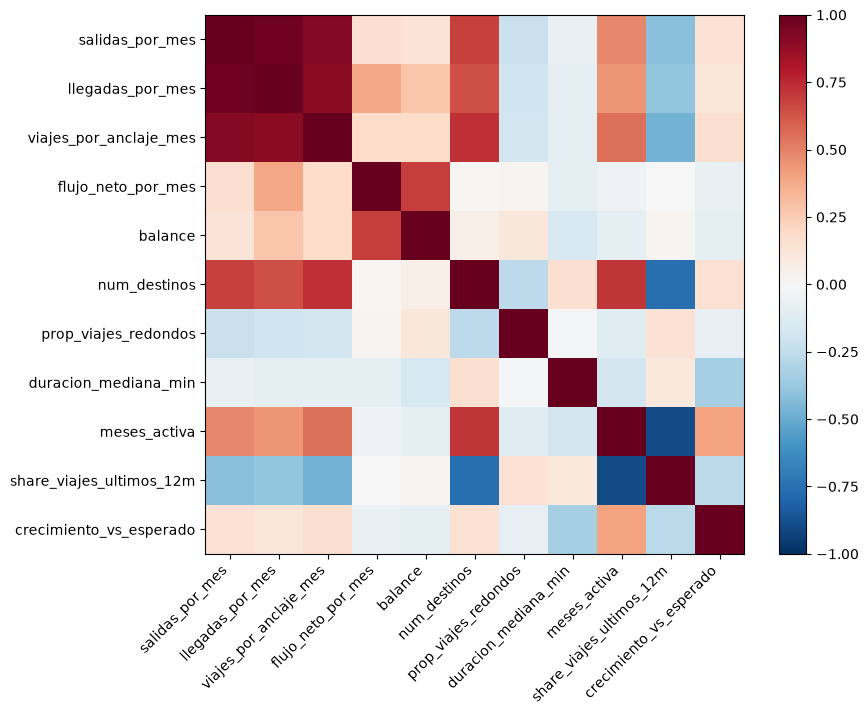

In [13]:
# Objetivo: revisar la correlación entre las características interpretables.
# Resultado esperado: mapa de calor; pares muy correlacionados candidatos a fusionarse.

interpretables = ["salidas_por_mes", "llegadas_por_mes", "viajes_por_anclaje_mes",
                  "flujo_neto_por_mes", "balance", "num_destinos",
                  "prop_viajes_redondos", "duracion_mediana_min", "meses_activa",
                  "share_viajes_ultimos_12m", "crecimiento_vs_esperado"]
corr = matriz[interpretables].corr()
fig, ax = plt.subplots(figsize=(9, 7))
imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(interpretables)), interpretables, rotation=45, ha="right")
ax.set_yticks(range(len(interpretables)), interpretables)
fig.colorbar(imagen);

### Conclusiones y lo que pasa a `features.py` / `train_p3.py`

- La matriz final queda con ~470 estaciones y 42 características en seis grupos: nivel de actividad, firma horaria (24), firma semanal (7), rol en la red, tipo de viaje y evolución histórica.
- Las escalas difieren en órdenes de magnitud (proporciones 0-1 contra salidas por mes de miles): se estandariza con `StandardScaler` antes de cualquier algoritmo por distancia.
- `salidas_por_mes` y `llegadas_por_mes` quedan casi duplicadas por correlación, pero se conservan porque el desbalance neto ya lo capturan `balance` y `flujo_neto_por_mes`, y K-Means tolera la redundancia.
- Siguiente paso: el notebook `2.1` selecciona el número de grupos, compara algoritmos y evalúa la estabilidad.